# Bab 7 — Unsupervised Learning

### Identitas Mahasiswa

| Detail | Identitas |
|---|---|
| Nama | Hadi Nugroho |
| NIM | 101032330235 |

**Tujuan pembelajaran.** memahami principal components analysis (PCA) dan cara membaca loadings; memahami correspondence analysis untuk data kategori; menjalankan dan menafsirkan K-means, hierarchical clustering, dan model-based clustering (Gaussian mixture); memilih jumlah cluster dengan elbow dan BIC; memahami pengaruh skala, variabel dominan, dan data kategori (Gower's distance) terhadap hasil clustering.

**Ringkasan bab.** Bab 1–6 selalu punya variabel target. Di bab ini tidak ada target: tujuannya menemukan struktur di dalam data itu sendiri. PCA meringkas banyak variabel numerik yang saling berkorelasi menjadi sedikit kombinasi linear (principal components) yang menyimpan sebagian besar variasi. Clustering mengelompokkan record yang mirip: K-means meminimalkan jarak kuadrat ke pusat cluster, hierarchical clustering membangun pohon penggabungan (dendrogram) dari matriks jarak, dan model-based clustering menganggap data berasal dari campuran distribusi normal multivariat lalu memilih jumlah komponen dengan BIC. Semua metode ini berbasis jarak atau variansi, sehingga skala variabel dan tipe data (numerik vs kategori) sangat menentukan hasil. Teknik unsupervised juga sering menjadi langkah awal sebelum model supervised, misalnya untuk reduksi dimensi atau membuat fitur segmen.

Notebook belajar dan reproduksi edisi kedua (Bruce, Bruce, Gedeck, 2020). Penjelasan ditulis ulang dengan bantuan AI; kode diadaptasi dari repository resmi berlisensi GPL-3.0. Bagian tambahan diberi label.

## Setup dan dataset

| File | Unit observasi dan kolom | Catatan |
|---|---|---|
| `sp500_data.csv.gz` | 5.647 hari perdagangan × 517 simbol | Nilai berupa perubahan harga harian yang disediakan buku (ada nilai negatif), bukan harga penutupan. Indeks berupa tanggal |
| `sp500_sectors.csv` | 517 simbol beserta sektor | Hanya dipakai di bagian tambahan untuk memberi label sektor |
| `housetasks.csv` | 13 pekerjaan rumah tangga × 4 kategori pelaku | Tabel frekuensi (contingency table) untuk correspondence analysis; **file baru** di repository ini |
| `loan_data.csv.gz` | 45.342 pinjaman Lending Club | Sama seperti Bab 5–6; bab ini hanya memakai pinjaman default dan beberapa kolom numerik/kategori |

Kode buku memakai `prince` untuk correspondence analysis dan `adjustText` untuk merapikan label. Untuk Gower's distance, kode Python buku hanya berisi komentar karena belum ada implementasi di paket populer; notebook ini menulis fungsi Gower sendiri (diberi label tambahan) agar contoh R buku tetap bisa direproduksi.

Sumber file: [repository pendamping edisi kedua](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa/data). Commit sumber dan checksum dicatat di `data/manifest.json`.

In [1]:
%matplotlib inline
import math
import sys
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import cm
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data/manifest.json").exists():
    raise FileNotFoundError("Buka folder proyek sebagai workspace dan jalankan notebook dari root proyek.")
DATA = ROOT / "data"
SEED = 1
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 110})
pd.set_option("display.max_columns", 25)

import sklearn, scipy, prince
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.stats import multivariate_normal
from adjustText import adjust_text

print("Python:", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__, "| prince", prince.__version__)

sp500_px = pd.read_csv(DATA / 'sp500_data.csv.gz', index_col=0)
sp500_sym = pd.read_csv(DATA / 'sp500_sectors.csv')
housetasks = pd.read_csv(DATA / 'housetasks.csv', index_col=0)
loan_data = pd.read_csv(DATA / 'loan_data.csv.gz', index_col=0)
loan_data['outcome'] = pd.Categorical(loan_data['outcome'], categories=['paid off', 'default'], ordered=True)
defaults = loan_data.loc[loan_data['outcome'] == 'default', :]
print('sp500_px:', sp500_px.shape, '| periode:', sp500_px.index.min(), 's.d.', sp500_px.index.max())
print('housetasks:', housetasks.shape, '| loan_data:', loan_data.shape, '| defaults:', defaults.shape)

Python: 3.13.17 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.16.3 | prince 0.22.2


sp500_px: (5647, 517) | periode: 1993-01-29 s.d. 2015-07-01
housetasks: (13, 4) | loan_data: (45342, 20) | defaults: (22671, 20)


<a id="c7-01"></a>
## Principal Components Analysis

*Jenis: Teori.*

Variabel numerik sering bergerak bersama: saham dua perusahaan minyak biasanya naik-turun di hari yang sama. PCA mencari kombinasi linear baru dari variabel-variabel tersebut,
$$Z_i = w_{i,1}X_1 + w_{i,2}X_2 + \dots + w_{i,p}X_p,$$
dengan syarat komponen pertama $Z_1$ punya variansi sebesar mungkin, komponen kedua $Z_2$ punya variansi terbesar berikutnya **dan** tidak berkorelasi dengan $Z_1$, dan seterusnya. Bobot $w_{i,j}$ disebut **loadings**, nilai $Z_i$ untuk tiap record disebut **scores**. Kalau beberapa komponen pertama sudah menangkap sebagian besar variansi, data berdimensi $p$ bisa diringkas menjadi sedikit dimensi saja. Istilah penting: *principal component*, *loadings*, *screeplot* (plot variansi tiap komponen).

<a id="c7-02"></a>
## A Simple Example

*Jenis: Reproduksi Python buku.*

Contoh pertama hanya memakai dua saham minyak, Chevron (CVX) dan ExxonMobil (XOM), pada seluruh periode data. Dengan dua variabel, PCA menghasilkan dua komponen, dan arah loadings bisa digambar sebagai garis di atas scatterplot.

,XOM,CVX
1993-01-29,-0.016991,0.072921
1993-02-01,0.016991,0.102089
1993-02-02,0.084954,0.029168
1993-02-03,0.067964,0.058337
1993-02-04,0.034378,0.044272


Loadings (baris 0 = PC1, baris 1 = PC2):


,XOM,CVX
0,0.664711,0.747101
1,0.747101,-0.664711


Variansi tiap komponen: [0.7782 0.0905] | proporsi: [0.8959 0.1041]


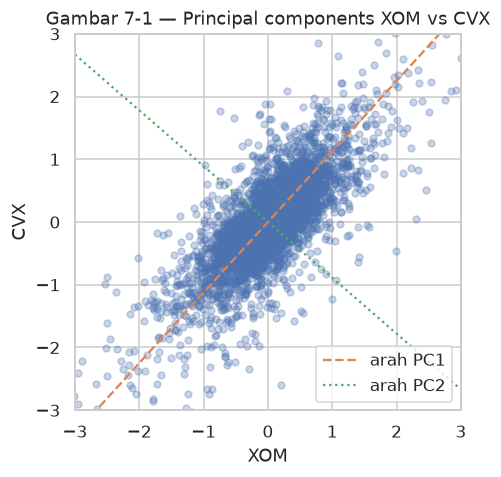

In [2]:
oil_px = sp500_px[['XOM', 'CVX']]
display(oil_px.head())

pcs = PCA(n_components=2)
pcs.fit(oil_px)
loadings = pd.DataFrame(pcs.components_, columns=oil_px.columns)
print('Loadings (baris 0 = PC1, baris 1 = PC2):')
display(loadings)
print('Variansi tiap komponen:', pcs.explained_variance_.round(4),
      '| proporsi:', pcs.explained_variance_ratio_.round(4))

def abline(slope, intercept, ax):
    # Koordinat garis dari slope dan intercept (fungsi bantu dari kode buku)
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)

ax = oil_px.plot.scatter(x='XOM', y='CVX', alpha=0.3, figsize=(4.5, 4.5))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.plot(*abline(loadings.loc[0, 'CVX'] / loadings.loc[0, 'XOM'], 0, ax), '--', color='C1', label='arah PC1')
ax.plot(*abline(loadings.loc[1, 'CVX'] / loadings.loc[1, 'XOM'], 0, ax), ':', color='C2', label='arah PC2')
ax.set_title('Gambar 7-1 — Principal components XOM vs CVX'); ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Loadings PC1 adalah (XOM 0,665; CVX 0,747): keduanya positif dan hampir sama besar, jadi PC1 kira-kira "rata-rata pergerakan dua saham minyak". Karena XOM dan CVX biasanya naik-turun bersama, PC1 saja sudah menjelaskan 89,6% variansi. PC2 (0,747; −0,665) adalah selisih keduanya, yaitu hari ketika XOM dan CVX bergerak berlawanan; porsinya hanya 10,4%. Di grafik, garis PC1 mengikuti arah sebaran terpanjang (diagonal) dan PC2 tegak lurus terhadapnya. Output Python buku mencetak PC1 dengan tanda negatif (−0,665; −0,747); tanda eigenvector arbitrer, jadi maknanya sama persis.

<a id="c7-03"></a>
## Computing the Principal Components

*Jenis: Teori + verifikasi tambahan.*

Langkah PCA menurut buku: (1) komponen pertama dipilih sebagai kombinasi linear yang memaksimalkan persentase variansi total yang dijelaskan; (2) komponen kedua dicari dengan cara sama pada sisa variansi, dengan syarat tidak berkorelasi dengan komponen pertama; (3) proses diulang sampai jumlah komponen sama dengan jumlah variabel. Secara aljabar linear, loadings adalah **eigenvector** dari matriks kovarians data yang sudah dipusatkan, dan variansi tiap komponen adalah **eigenvalue**-nya:
$$\Sigma\,w_i = \lambda_i w_i,\qquad \operatorname{Var}(Z_i)=\lambda_i,\qquad \lambda_1\ge\lambda_2\ge\dots$$
scikit-learn menghitungnya lewat SVD dari matriks data terpusat (lebih stabil secara numerik), tetapi hasilnya sama. Sel tambahan di bawah memverifikasi hal ini untuk contoh XOM–CVX, dan juga memeriksa bahwa scores kedua komponen memang tidak berkorelasi. Tanda (positif/negatif) eigenvector bersifat arbitrer: $w$ dan $-w$ sama-sama benar.

In [3]:
# Tambahan: PCA = eigen-decomposition matriks kovarians data terpusat
X = oil_px.to_numpy()
cov = np.cov(X, rowvar=False)
eigval, eigvec = np.linalg.eigh(cov)                 # eigh mengurutkan dari kecil ke besar
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
print('Matriks kovarians:\n', cov.round(4))
print('Eigenvalue          :', eigval.round(4))
print('explained_variance_ :', pcs.explained_variance_.round(4))
same = [np.allclose(np.abs(eigvec[:, i]), np.abs(pcs.components_[i]), atol=1e-8) for i in range(2)]
print('Eigenvector = loadings (abaikan tanda)?', same)

scores = pcs.transform(oil_px)                       # Z = (X - mean) @ W^T
print('Korelasi score PC1 dan PC2:', round(np.corrcoef(scores.T)[0, 1], 10))
print('Variansi score:', scores.var(axis=0, ddof=1).round(4))

Matriks kovarians:
 [[0.3943 0.3415]
 [0.3415 0.4743]]
Eigenvalue          : [0.7782 0.0905]
explained_variance_ : [0.7782 0.0905]
Eigenvector = loadings (abaikan tanda)? [True, True]
Korelasi score PC1 dan PC2: 0.0
Variansi score: [0.7782 0.0905]


**Interpretasi dan catatan belajar.** Eigenvalue matriks kovarians (0,7782 dan 0,0905) sama dengan `explained_variance_`, dan eigenvector-nya sama dengan loadings (hanya tanda yang boleh berbeda). Score PC1 dan PC2 berkorelasi 0, dan variansi score tiap komponen tepat sama dengan eigenvalue-nya. Total variansi juga tidak berubah: 0,3943 + 0,4743 = 0,8686 = 0,7782 + 0,0905. Jadi PCA hanya **memutar** sumbu koordinat ke arah sebaran terbesar, tanpa membuang informasi selama semua komponen dipertahankan; reduksi dimensi terjadi ketika kita memilih membuang komponen bervariansi kecil.

<a id="c7-04"></a>
## Interpreting Principal Components

*Jenis: Reproduksi Python buku.*

Untuk 16 saham besar sejak 2011, buku menampilkan dua alat bantu tafsir: **screeplot** (variansi tiap komponen) untuk melihat berapa komponen yang penting, dan **bar chart loadings** lima komponen teratas untuk melihat variabel apa yang "membentuk" tiap komponen.

top_sp: (1131, 16)


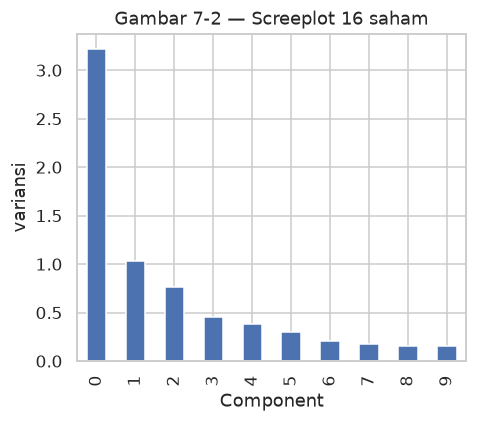

,proporsi,kumulatif
PC1,0.4448,0.4448
PC2,0.1434,0.5883
PC3,0.1050,0.6933
PC4,0.0622,0.7555
PC5,0.0531,0.8086
PC6,0.0416,0.8502


In [4]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]
print('top_sp:', top_sp.shape)

sp_pca = PCA()
sp_pca.fit(top_sp)

explained_variance = pd.DataFrame(sp_pca.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4.5, 4))
ax.set_xlabel('Component'); ax.set_ylabel('variansi'); ax.set_title('Gambar 7-2 — Screeplot 16 saham')
plt.tight_layout(); plt.show()

# Tambahan: proporsi dan kumulatif variansi yang dijelaskan
evr = pd.DataFrame({'proporsi': sp_pca.explained_variance_ratio_,
                    'kumulatif': sp_pca.explained_variance_ratio_.cumsum()},
                   index=[f'PC{i+1}' for i in range(len(syms))])
display(evr.head(6).round(4))

,AAPL,AXP,COP,COST,CSCO,CVX,HD,INTC,JPM,MSFT,SLB,TGT,USB,WFC,WMT,XOM
0,0.301,0.246,0.262,0.274,0.064,0.444,0.208,0.077,0.196,0.105,0.482,0.149,0.116,0.146,0.122,0.318
1,0.505,0.139,-0.174,0.416,0.032,-0.289,0.278,0.034,0.041,0.054,-0.472,0.228,0.055,0.047,0.223,-0.154
2,0.787,-0.135,0.002,-0.466,0.008,-0.082,-0.166,0.004,-0.062,-0.016,0.195,-0.161,-0.049,-0.042,-0.176,-0.090
3,-0.121,0.062,-0.206,0.093,0.004,-0.578,0.163,-0.002,0.058,-0.013,0.681,0.110,0.017,0.019,0.058,-0.295
4,-0.112,0.597,0.006,-0.556,0.040,-0.109,0.185,0.072,0.385,0.077,-0.181,0.056,0.155,0.216,-0.092,-0.013


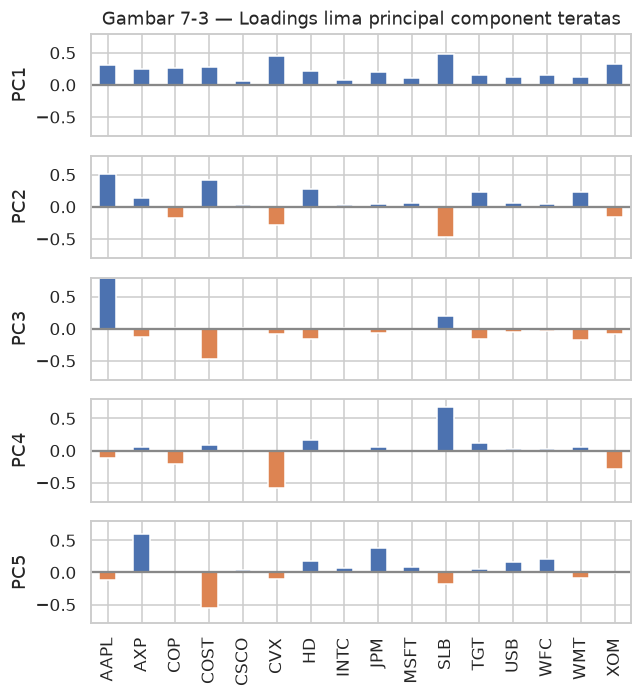

In [5]:
loadings = pd.DataFrame(sp_pca.components_[0:5, :], columns=top_sp.columns)
display(loadings.round(3))

maxPC = 1.01 * loadings.loc[0:5, :].abs().to_numpy().max()
f, axes = plt.subplots(5, 1, figsize=(6, 6.5), sharex=True)
for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ['C0' if l > 0 else 'C1' for l in pc_loadings]
    ax.axhline(color='#888888')
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-maxPC, maxPC)
axes[0].set_title('Gambar 7-3 — Loadings lima principal component teratas')
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Screeplot menunjukkan PC1 jauh dominan (44,5% variansi), disusul PC2 14,3% dan PC3 10,5%; lima komponen pertama menjelaskan 80,9%. Tafsir loadings:

- **PC1**: semua loadings positif (0,06–0,48). Komponen ini adalah "faktor pasar": hari ketika hampir semua saham naik atau turun bersama. Saham energi (SLB 0,48; CVX 0,44; XOM 0,32) punya loadings terbesar karena perubahan hariannya dalam dolar paling besar (data tidak distandardisasi).
- **PC2**: positif untuk AAPL (0,505), COST (0,416), HD, TGT, WMT; negatif untuk SLB (−0,472), CVX (−0,289), COP, XOM. Ini kontras **energi vs non-energi**.
- **PC3**: didominasi AAPL (0,787) melawan COST (−0,466), pergerakan khas Apple.
- **PC4**: SLB (0,681) melawan CVX (−0,578) dan XOM, kontras **di dalam** sektor energi.
- **PC5**: AXP (0,597) dan JPM (0,385) melawan COST (−0,556), terutama saham keuangan.

Pola ini sama dengan tafsir di buku. Saham dengan perubahan harian kecil (CSCO, INTC, MSFT) hampir tidak muncul di lima komponen pertama; ini efek skala yang dibahas di bagian *Dominant Variables*.

<a id="c7-05"></a>
## Correspondence Analysis

*Jenis: Reproduksi Python buku.*

PCA hanya untuk variabel numerik. Untuk data kategori, analog utamanya adalah **correspondence analysis (CA)**. Inputnya contingency table (frekuensi dua variabel kategori). CA mengubah tabel itu menjadi koordinat sedemikian sehingga baris dan kolom yang sering muncul bersama terletak berdekatan di peta dua dimensi (*biplot*). Secara matematis, CA adalah SVD dari matriks residual standar chi-square $(O-E)/\sqrt{E}$, sehingga jarak di peta mencerminkan penyimpangan dari independensi.

Contoh buku: siapa yang mengerjakan 13 pekerjaan rumah tangga (istri, suami, bergantian, bersama).

,Wife,Alternating,Husband,Jointly
Task,,,,
Laundry,156,14,2,4
Main_meal,124,20,5,4
Dinner,77,11,7,13
Breakfast,82,36,15,7
Tidying,53,11,1,57
Dishes,32,24,4,53
Shopping,33,23,9,55
Official,12,46,23,15
Driving,10,51,75,3


,eigenvalue,% of variance,% of variance (cumulative)
component,,,
0,0.543,48.69%,48.69%
1,0.445,39.91%,88.60%


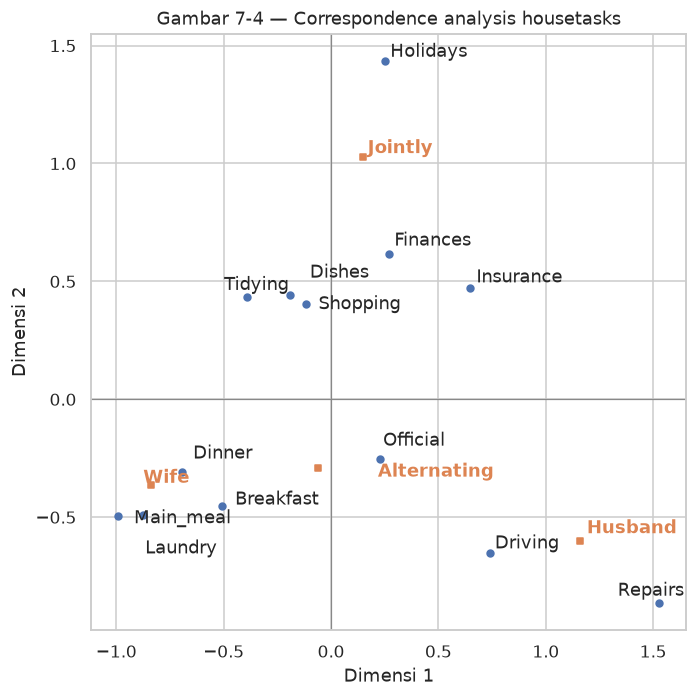

In [6]:
display(housetasks)

ca = prince.CA(n_components=2)
ca = ca.fit(housetasks)
display(ca.eigenvalues_summary)

row_coord = ca.row_coordinates(housetasks)
col_coord = ca.column_coordinates(housetasks)
ax = row_coord.plot.scatter(x=0, y=1, figsize=(6.5, 6.5))
col_coord.plot.scatter(x=0, y=1, ax=ax, c='C1', marker='s')
texts = []
for idx, row in row_coord.iterrows():
    texts.append(plt.text(row.iloc[0], row.iloc[1], idx))
for idx, row in col_coord.iterrows():
    texts.append(plt.text(row.iloc[0], row.iloc[1], idx, color='C1', fontweight='bold'))
adjust_text(texts, only_move={'points': 'y', 'texts': 'y'})
ax.axhline(0, color='#888888', lw=.8); ax.axvline(0, color='#888888', lw=.8)
ax.set(xlabel='Dimensi 1', ylabel='Dimensi 2', title='Gambar 7-4 — Correspondence analysis housetasks')
plt.tight_layout(); plt.show()

In [7]:
# Tambahan: cek independensi dan hubungkan inertia CA dengan statistik chi-square
from scipy.stats import chi2_contingency
chi2, p_value, dof, expected = chi2_contingency(housetasks)
total_inertia = chi2 / housetasks.to_numpy().sum()
print(f'Chi-square = {chi2:.2f}, df = {dof}, p-value = {p_value:.3g}')
print(f'Total inertia (chi2 / n) = {total_inertia:.4f}; dua dimensi pertama = {ca.eigenvalues_.sum():.4f} '
      f'({ca.eigenvalues_.sum() / total_inertia:.1%})')
print('Persentase baris (siapa yang mengerjakan tiap tugas):')
display((housetasks.div(housetasks.sum(axis=1), axis=0) * 100).round(0).astype(int))

Chi-square = 1944.46, df = 36, p-value = 0
Total inertia (chi2 / n) = 1.1149; dua dimensi pertama = 0.9879 (88.6%)
Persentase baris (siapa yang mengerjakan tiap tugas):


,Wife,Alternating,Husband,Jointly
Task,,,,
Laundry,89,8,1,2
Main_meal,81,13,3,3
Dinner,71,10,6,12
Breakfast,59,26,11,5
Tidying,43,9,1,47
Dishes,28,21,4,47
Shopping,28,19,8,46
Official,12,48,24,16
Driving,7,37,54,2


**Interpretasi dan catatan belajar.** Uji chi-square (χ² = 1944,5; df 36; p ≈ 0) menunjukkan pembagian kerja sangat tidak independen dari jenis pekerjaan. Dua dimensi CA menjelaskan 48,7% + 39,9% = **88,6%** dari total inertia (1,115 = χ²/n), jadi peta dua dimensi sudah mewakili hampir seluruh asosiasi. Di peta terlihat tiga kelompok:

- **Wife** (kiri bawah) dekat Laundry, Main_meal, Dinner, Breakfast; tabel persentase baris mengonfirmasi, misalnya 89% laundry dikerjakan istri.
- **Husband** (kanan bawah) dekat Repairs dan Driving; 97% perbaikan dikerjakan suami.
- **Jointly** (atas) dekat Holidays, Finances, Insurance; 96% urusan liburan dikerjakan bersama.

**Alternating** berada dekat titik asal bersama Official, karena kategori ini tidak terlalu khas untuk pekerjaan tertentu. Tidying, Dishes, dan Shopping berada di antara Wife dan Jointly, sesuai persentasenya yang terbagi (±28–43% istri, ±46–47% bersama). Orientasi sumbu bisa terbalik dibanding gambar R di buku; yang bermakna adalah jarak relatif antartitik.

<a id="c7-06"></a>
## K-Means Clustering

*Jenis: Teori.*

Clustering membagi data ke dalam kelompok sehingga record dalam satu kelompok mirip satu sama lain. K-means adalah metode clustering pertama yang populer dan masih sangat sering dipakai. Data dibagi menjadi $K$ cluster dengan meminimalkan **within-cluster sum of squares**:
$$\text{SS} = \sum_{k=1}^{K}\sum_{i\in C_k}\lVert x_i-\bar x_k\rVert^2,$$
yaitu total kuadrat jarak Euclidean setiap record ke rata-rata (centroid) cluster-nya. K-means tidak menjamin ukuran cluster sama, tetapi cluster yang dihasilkan "sejauh mungkin" terpisah. Istilah penting: *cluster*, *cluster mean / centroid*, $K$.

<a id="c7-07"></a>
## A Simple Example

*Jenis: Reproduksi Python buku; `random_state` ditambahkan.*

Data XOM dan CVX sejak 2011 dibagi menjadi 4 cluster. Karena hanya dua variabel yang skalanya sama (perubahan harga harian dalam dolar), standardisasi tidak diperlukan di contoh ini. Kode buku tidak mengunci seed, sehingga nomor cluster bisa berganti setiap dijalankan; di sini ditambahkan `random_state=SEED`.

,XOM,CVX,cluster
2011-01-03,0.736805,0.240681,3
2011-01-04,0.168668,-0.584516,0
2011-01-05,0.026631,0.446985,3
2011-01-06,0.248558,-0.919751,0
2011-01-07,0.337329,0.180511,3


,XOM,CVX
0,-0.2864,-0.4930
1,1.0921,1.5811
2,-1.1230,-1.7188
3,0.3258,0.4500


Ukuran cluster: {0: 421, 1: 123, 2: 118, 3: 469}


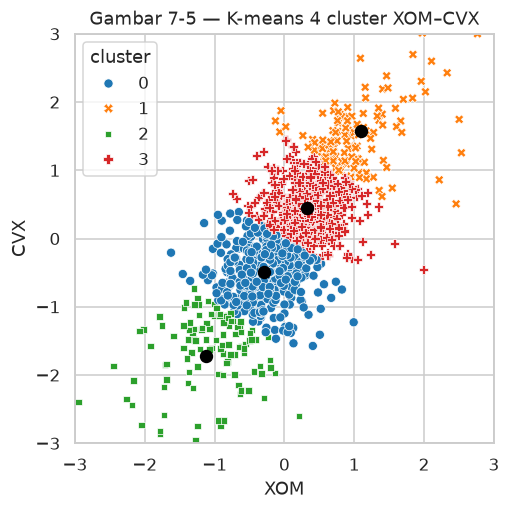

In [8]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']].copy()
kmeans = KMeans(n_clusters=4, n_init='auto', random_state=SEED).fit(df)
df['cluster'] = kmeans.labels_
display(df.head())

centers = pd.DataFrame(kmeans.cluster_centers_, columns=['XOM', 'CVX'])
display(centers.round(4))
print('Ukuran cluster:', dict(sorted(Counter(kmeans.labels_.tolist()).items())))

fig, ax = plt.subplots(figsize=(4.8, 4.8))
ax = sns.scatterplot(x='XOM', y='CVX', hue='cluster', style='cluster', ax=ax, data=df, palette='tab10')
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
centers.plot.scatter(x='XOM', y='CVX', ax=ax, s=60, color='black')
ax.set_title('Gambar 7-5 — K-means 4 cluster XOM–CVX')
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Empat pusat cluster tersusun di sepanjang diagonal: cluster 2 (XOM −1,12; CVX −1,72) adalah hari turun tajam, cluster 0 (−0,29; −0,49) turun ringan, cluster 3 (0,33; 0,45) naik ringan, dan cluster 1 (1,09; 1,58) naik tajam. Ukurannya 421, 123, 118, dan 469 hari: hari "biasa" jauh lebih banyak daripada hari ekstrem. K-means membagi awan data yang sebenarnya menyatu menjadi potongan-potongan sepanjang arah PC1. Ini tetap berguna untuk segmentasi, tetapi tidak berarti ada empat kelompok alami yang terpisah jelas.

<a id="c7-08"></a>
## K-Means Algorithm

*Jenis: Teori + implementasi manual tambahan.*

Mencari partisi yang benar-benar optimal sulit secara komputasi, jadi dipakai algoritme heuristik (Lloyd): (1) mulai dari $K$ pusat awal; (2) **assign** setiap record ke pusat terdekat; (3) **update** setiap pusat menjadi rata-rata record anggotanya; (4) ulangi langkah 2–3 sampai keanggotaan tidak berubah. Setiap langkah tidak pernah menaikkan SS, sehingga algoritme pasti berhenti, tetapi bisa berhenti di optimum lokal. Karena itu algoritme dijalankan berkali-kali dari titik awal acak yang berbeda (`n_init`) dan hasil dengan SS terkecil yang dipilih. scikit-learn memakai inisialisasi *k-means++* yang menyebar pusat awal.

Sel tambahan menulis algoritme Lloyd dengan NumPy, memakai pusat awal yang sama untuk versi manual dan scikit-learn, lalu membandingkan hasilnya. Sel berikutnya adalah kode buku untuk 16 saham dengan 5 cluster.

In [9]:
# Tambahan: algoritme Lloyd manual
def kmeans_lloyd(X, init_centers, max_iter=100):
    centers = init_centers.copy()
    history = []
    for it in range(max_iter):
        d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)   # jarak kuadrat ke tiap pusat
        labels = d2.argmin(axis=1)                                      # langkah assign
        sse = d2[np.arange(len(X)), labels].sum()
        history.append(sse)
        new_centers = np.array([X[labels == k].mean(axis=0) for k in range(len(centers))])  # langkah update
        if np.allclose(new_centers, centers):
            break
        centers = new_centers
    return labels, centers, history

X_oil = df[['XOM', 'CVX']].to_numpy()
rng = np.random.default_rng(SEED)
init = X_oil[rng.choice(len(X_oil), 4, replace=False)]
labels_m, centers_m, sse_hist = kmeans_lloyd(X_oil, init)
km_same_init = KMeans(n_clusters=4, init=init, n_init=1, algorithm='lloyd').fit(X_oil)
print('Iterasi sampai konvergen:', len(sse_hist))
print('SS per iterasi (5 pertama):', np.round(sse_hist[:5], 2), '... akhir:', round(sse_hist[-1], 2))
print('SS sklearn (init sama)    :', round(km_same_init.inertia_, 2))
print('Label manual = label sklearn?', np.array_equal(labels_m, km_same_init.labels_))
print('SS sklearn k-means++ (n_init auto) dari sel sebelumnya:', round(kmeans.inertia_, 2))

Iterasi sampai konvergen: 25
SS per iterasi (5 pertama): [835.39 547.66 506.79 481.05 457.06] ... akhir: 408.89
SS sklearn (init sama)    : 408.89
Label manual = label sklearn? True
SS sklearn k-means++ (n_init auto) dari sel sebelumnya: 410.5


In [10]:
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]
kmeans = KMeans(n_clusters=5, n_init='auto', random_state=SEED).fit(top_sp)
print('Inertia (SS) 5 cluster:', round(kmeans.inertia_, 2))

Inertia (SS) 5 cluster: 4756.99


**Interpretasi dan catatan belajar.** Implementasi manual konvergen setelah 25 iterasi; SS turun monoton dari 835,39 ke 408,89, dan hasilnya identik dengan scikit-learn (`algorithm='lloyd'`) bila pusat awalnya sama. Menariknya, hasil k-means++ di sel sebelumnya punya SS sedikit lebih besar (410,50). Dengan `n_init='auto'` dan inisialisasi k-means++, scikit-learn hanya menjalankan **satu** inisialisasi, sehingga bisa berakhir di optimum lokal yang sedikit lebih buruk. Ini contoh nyata mengapa buku menyarankan beberapa inisialisasi acak (`nstart` di R, `n_init` di Python). Untuk 16 saham dan 5 cluster, SS akhirnya 4.756,99.

<a id="c7-09"></a>
## Interpreting the Clusters

*Jenis: Reproduksi Python buku.*

Dua hal yang dilihat: **ukuran** tiap cluster (cluster yang sangat kecil biasanya berisi outlier) dan **pusat** cluster, yaitu rata-rata tiap variabel di cluster itu. Pada data saham, setiap record adalah satu hari, jadi pusat cluster menggambarkan "pola hari" yang khas.

Ukuran cluster: {0: 256, 1: 271, 2: 130, 3: 152, 4: 322}


,AAPL,AXP,COP,COST,CSCO,CVX,HD,INTC,JPM,MSFT,SLB,TGT,USB,WFC,WMT,XOM
0,-0.565,-0.222,0.038,-0.511,-0.039,0.055,-0.349,-0.037,-0.090,-0.068,0.082,-0.270,-0.095,-0.099,-0.260,-0.008
1,0.445,0.084,-0.314,0.230,0.024,-0.493,0.185,0.027,0.017,0.038,-0.642,0.125,0.025,0.009,0.142,-0.247
2,0.813,0.552,0.732,0.605,0.173,1.296,0.528,0.229,0.520,0.281,1.621,0.307,0.325,0.391,0.306,0.969
3,-1.079,-0.829,-0.788,-0.768,-0.201,-1.333,-0.579,-0.244,-0.660,-0.325,-1.427,-0.478,-0.354,-0.458,-0.280,-0.918
4,0.099,0.336,0.259,0.404,0.073,0.462,0.300,0.098,0.200,0.119,0.392,0.240,0.135,0.165,0.216,0.362


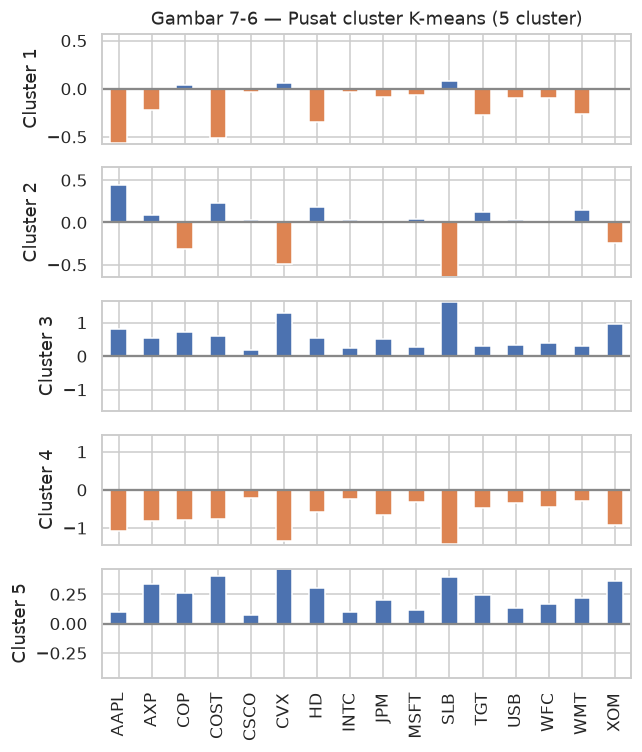

In [11]:
print('Ukuran cluster:', dict(sorted(Counter(kmeans.labels_.tolist()).items())))

centers = pd.DataFrame(kmeans.cluster_centers_, columns=syms)
display(centers.round(3))

f, axes = plt.subplots(5, 1, figsize=(6, 7), sharex=True)
for i, ax in enumerate(axes):
    center = centers.loc[i, :]
    maxPC = 1.01 * np.max(np.max(np.abs(center)))
    colors = ['C0' if l > 0 else 'C1' for l in center]
    ax.axhline(color='#888888')
    center.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'Cluster {i + 1}')
    ax.set_ylim(-maxPC, maxPC)
axes[0].set_title('Gambar 7-6 — Pusat cluster K-means (5 cluster)')
plt.tight_layout(); plt.show()

In [12]:
# Tambahan: ringkasan pola tiap cluster (rata-rata perubahan semua saham dan per kelompok sektor)
groups = {'teknologi': ['AAPL', 'MSFT', 'CSCO', 'INTC'], 'energi': ['CVX', 'XOM', 'SLB', 'COP'],
          'keuangan': ['JPM', 'WFC', 'USB', 'AXP'], 'ritel': ['WMT', 'TGT', 'HD', 'COST']}
summary = pd.DataFrame({g: centers[s].mean(axis=1) for g, s in groups.items()})
summary.insert(0, 'semua saham', centers.mean(axis=1))
summary.insert(0, 'jumlah hari', pd.Series(Counter(kmeans.labels_)).sort_index())
summary.index = [f'Cluster {i + 1}' for i in range(5)]
display(summary.round(3))

,jumlah hari,semua saham,teknologi,energi,keuangan,ritel
Cluster 1,256,-0.152,-0.177,0.042,-0.126,-0.348
Cluster 2,271,-0.022,0.133,-0.424,0.034,0.170
Cluster 3,130,0.603,0.374,1.154,0.447,0.436
Cluster 4,152,-0.670,-0.462,-1.117,-0.575,-0.526
Cluster 5,322,0.241,0.097,0.369,0.209,0.290


**Interpretasi dan catatan belajar.** Ukuran cluster 256, 271, 130, 152, dan 322 hari, tidak ada cluster yang sangat kecil. Tabel tambahan memudahkan membaca grafik:

- **Cluster 3** (130 hari): semua saham naik kuat (rata-rata +0,60), energi paling besar (+1,15). Hari "pasar naik tajam".
- **Cluster 4** (152 hari): kebalikannya, semua turun (−0,67), energi −1,12. Hari "pasar turun tajam".
- **Cluster 5** (322 hari): semua naik moderat (+0,24).
- **Cluster 2** (271 hari): energi turun (−0,42) sementara teknologi (+0,13) dan ritel (+0,17) naik. Hari ketika sektor energi bergerak sendiri.
- **Cluster 1** (256 hari): ritel (−0,35) dan teknologi (AAPL −0,57) turun sementara energi datar (+0,04).

Jadi dua cluster mewakili arah pasar secara umum dan cluster sisanya mewakili pergerakan khas sektor, mirip temuan PCA: faktor pasar (PC1) dan kontras energi vs non-energi (PC2). Buku menafsirkan cluster-nya dengan pola yang sama; nomor cluster bisa berbeda karena bergantung pada seed.

<a id="c7-10"></a>
## Selecting the Number of Clusters

*Jenis: Reproduksi Python buku + pembanding tambahan.*

Kadang $K$ ditentukan kebutuhan bisnis (misalnya 5 segmen pelanggan). Kalau tidak, dipakai heuristik **elbow method**: hitung ukuran sebaran dalam cluster untuk beberapa $K$, lalu cari titik ketika penambahan cluster tidak lagi banyak mengurangi sebaran. Kode Python buku memplot `inertia_ / n_clusters`. Versi R buku memplot **persentase variansi yang dijelaskan** $=\text{between SS}/\text{total SS}$; versi ini ditambahkan, bersama **silhouette score** (seberapa jauh setiap record ke cluster lain dibanding ke cluster sendiri, rentang −1 sampai 1) sebagai pembanding.

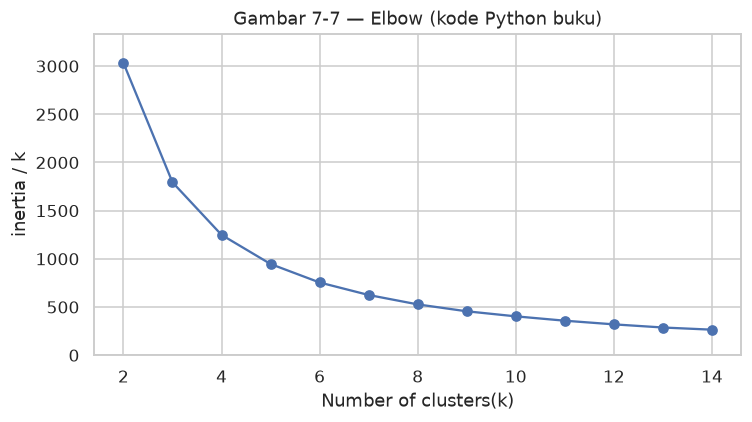

In [13]:
inertia = []
for n_clusters in range(2, 15):
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init='auto').fit(top_sp)
    inertia.append(kmeans.inertia_ / n_clusters)
inertias = pd.DataFrame({'n_clusters': range(2, 15), 'inertia': inertia})
ax = inertias.plot(x='n_clusters', y='inertia', marker='o')
plt.xlabel('Number of clusters(k)')
plt.ylabel('inertia / k')
plt.ylim((0, 1.1 * inertias.inertia.max()))
ax.legend().set_visible(False)
ax.set_title('Gambar 7-7 — Elbow (kode Python buku)')
plt.tight_layout(); plt.show()

,inertia,pct_var_explained,silhouette,tambahan_pct
k,,,,
2,6063.0974,0.2575,0.2231,NaN
3,5379.4352,0.3413,0.1555,0.0837
4,4992.4097,0.3886,0.1210,0.0474
5,4713.5985,0.4228,0.1094,0.0341
6,4502.4157,0.4486,0.1032,0.0259
7,4319.2171,0.4711,0.1019,0.0224
8,4188.2356,0.4871,0.0951,0.0160
9,4053.1850,0.5037,0.1008,0.0165
10,3963.6057,0.5146,0.0968,0.0110


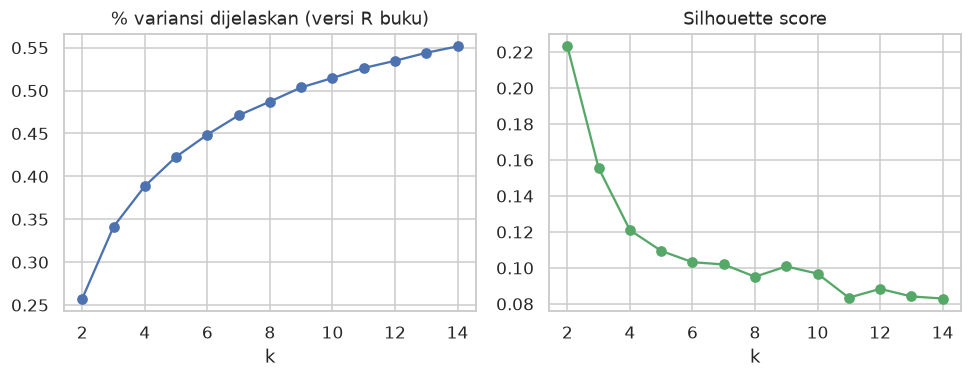

In [14]:
# Tambahan: persen variansi yang dijelaskan (seperti versi R buku) dan silhouette
total_ss = ((top_sp - top_sp.mean()) ** 2).to_numpy().sum()
rows = []
for k in range(2, 15):
    km = KMeans(n_clusters=k, random_state=0, n_init=10).fit(top_sp)
    rows.append({'k': k, 'inertia': km.inertia_, 'pct_var_explained': 1 - km.inertia_ / total_ss,
                 'silhouette': silhouette_score(top_sp, km.labels_, sample_size=1000, random_state=SEED)})
k_scan = pd.DataFrame(rows).set_index('k')
k_scan['tambahan_pct'] = k_scan['pct_var_explained'].diff()
display(k_scan.round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
k_scan['pct_var_explained'].plot(marker='o', ax=axes[0], title='% variansi dijelaskan (versi R buku)')
k_scan['silhouette'].plot(marker='o', ax=axes[1], color='C2', title='Silhouette score')
for a in axes: a.set_xlabel('k')
plt.tight_layout(); plt.show()

**Interpretasi dan catatan belajar.** Label sumbu-y kode buku, *Average Within-Cluster Squared Distances*, kurang tepat untuk `inertia_ / n_clusters`: nilai itu adalah total SS dibagi jumlah cluster, bukan rata-rata jarak kuadrat per record (yang seharusnya dibagi jumlah record). Karena itu label diganti menjadi `inertia / k`. Tabel tambahan menunjukkan persentase variansi yang dijelaskan naik dari 25,8% (k=2) ke 34,1% (k=3), 38,9% (k=4), dan 42,3% (k=5). Tambahan per cluster mengecil dari 8,4 poin (2→3) menjadi 3,4 poin (4→5) dan di bawah 2 poin setelah k=8. Tidak ada "siku" tajam; lengkungan paling jelas ada di sekitar k=3–5. Silhouette tertinggi di k=2 (0,22) lalu turun ke ±0,10 mulai k=5, nilai yang rendah. Artinya data harian saham adalah satu awan kontinu tanpa cluster yang terpisah tegas, sehingga pilihan K lebih ditentukan kebutuhan interpretasi daripada oleh data. K=5 di bagian sebelumnya masih wajar karena setiap cluster punya tafsir yang jelas.

<a id="c7-11"></a>
## Hierarchical Clustering

*Jenis: Teori.*

Hierarchical clustering adalah alternatif K-means yang hasilnya berbeda bentuk. Kelebihannya: tidak perlu menentukan $K$ di awal, hasilnya bisa divisualisasikan sebagai pohon (**dendrogram**), dan bisa memakai ukuran jarak apa pun (termasuk untuk data kategori). Kekurangannya: perlu matriks jarak semua pasangan record, sehingga memori dan waktu tumbuh kira-kira $O(n^2)$ (atau lebih); metode ini cocok untuk data puluhan ribu record ke bawah, tidak untuk jutaan. Istilah penting: *dendrogram*, *distance* (jarak antar-record), *dissimilarity* (jarak antar-cluster, disebut juga *linkage*).

<a id="c7-12"></a>
## A Simple Example

*Jenis: Reproduksi Python buku.*

Sekarang yang di-cluster adalah **saham**, bukan hari. Data 18 saham sejak 2011 ditranspos sehingga setiap baris adalah satu saham dan setiap kolom satu hari perdagangan. `linkage` dengan metode complete menghasilkan matriks penggabungan $Z$ berukuran $(n-1)\times 4$: dua cluster yang digabung, jarak penggabungan, dan jumlah anggota cluster baru.

In [15]:
syms1 = ['AAPL', 'AMZN', 'AXP', 'COP', 'COST', 'CSCO', 'CVX', 'GOOGL', 'HD',
         'INTC', 'JPM', 'MSFT', 'SLB', 'TGT', 'USB', 'WFC', 'WMT', 'XOM']
df = sp500_px.loc[sp500_px.index >= '2011-01-01', syms1].transpose()
print('Ukuran data (saham × hari):', df.shape)

Z = linkage(df, method='complete')
print('Ukuran Z:', Z.shape)
print('Lima penggabungan pertama [cluster a, cluster b, jarak, jumlah anggota]:')
print(pd.DataFrame(Z[:5], columns=['a', 'b', 'jarak', 'n']).round(2).to_string())

Ukuran data (saham × hari): (18, 1131)
Ukuran Z: (17, 4)
Lima penggabungan pertama [cluster a, cluster b, jarak, jumlah anggota]:
      a     b  jarak    n
0  14.0  15.0   8.59  2.0
1   5.0   9.0   8.71  2.0
2  11.0  19.0  11.44  3.0
3  18.0  20.0  13.54  5.0
4  10.0  21.0  17.54  6.0


<a id="c7-13"></a>
## The Dendrogram

*Jenis: Reproduksi Python buku + label sektor tambahan.*

Dendrogram menggambarkan urutan penggabungan: daun adalah saham, tinggi sambungan adalah jarak saat dua cluster digabung. Memotong pohon secara horizontal (di sini dengan `fcluster(..., 4, criterion='maxclust')`) menghasilkan pembagian menjadi 4 cluster.

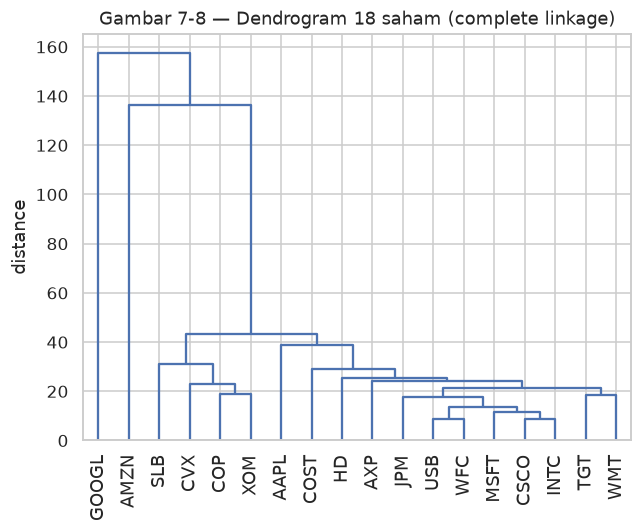

1 : COP, CVX, SLB, XOM
2 : AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
3 : AMZN
4 : GOOGL


,cluster,sektor,std perubahan harian
COP,1,energy,0.63
CVX,1,energy,0.97
SLB,1,energy,1.11
XOM,1,energy,0.72
HD,2,consumer_discretionary,0.70
TGT,2,consumer_discretionary,0.56
COST,2,consumer_staples,0.87
WMT,2,consumer_staples,0.51
AXP,2,financials,0.69
JPM,2,financials,0.54


In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
dendrogram(Z, labels=list(df.index), color_threshold=0, ax=ax)
plt.xticks(rotation=90)
ax.set_ylabel('distance'); ax.set_title('Gambar 7-8 — Dendrogram 18 saham (complete linkage)')
plt.tight_layout(); plt.show()

memb = fcluster(Z, 4, criterion='maxclust')
memb = pd.Series(memb, index=df.index)
for key, item in memb.groupby(memb):
    print(f"{key} : {', '.join(item.index)}")

# Tambahan: sektor tiap saham dari sp500_sectors.csv dan volatilitas hariannya
sector = sp500_sym.set_index('symbol')['sector']
display(pd.DataFrame({'cluster': memb, 'sektor': sector.reindex(memb.index),
                      'std perubahan harian': df.std(axis=1).round(2)}).sort_values(['cluster', 'sektor']))

**Interpretasi dan catatan belajar.** Pemotongan menjadi 4 cluster memberi: (1) COP, CVX, SLB, XOM, yaitu **seluruh saham energi**; (2) 12 saham lain dari sektor teknologi, keuangan, dan ritel; (3) AMZN sendiri; (4) GOOGL sendiri. Hasil ini sama dengan buku. AMZN dan GOOGL terpisah bukan karena polanya unik, tetapi karena **besarnya** perubahan harian: standar deviasinya 4,12 dan 4,76, jauh di atas saham lain (0,21–1,11). Jarak Euclidean pada data mentah sangat dipengaruhi skala. Kalau ingin mengelompokkan saham berdasarkan **pola** pergerakan bersama, data perlu distandardisasi lebih dulu atau memakai jarak berbasis korelasi ($1-r$).

<a id="c7-14"></a>
## The Agglomerative Algorithm

*Jenis: Teori + implementasi manual tambahan.*

Algoritme agglomerative: (1) mulai dengan setiap record sebagai cluster sendiri; (2) hitung dissimilarity semua pasangan cluster; (3) gabungkan pasangan dengan dissimilarity terkecil; (4) ulangi langkah 2–3 sampai tinggal satu cluster. Dengan **complete linkage**, jarak antar-cluster $A$ dan $B$ adalah jarak **terjauh** antara anggota keduanya:
$$D(A,B)=\max_{a\in A,\,b\in B} d(a,b).$$
Sel tambahan menjalankan algoritme ini secara manual untuk 6 saham dan membandingkan tinggi penggabungannya dengan `scipy.cluster.hierarchy.linkage`.

In [17]:
# Tambahan: agglomerative complete linkage manual untuk 6 saham
small = df.loc[['AAPL', 'MSFT', 'CVX', 'XOM', 'JPM', 'WFC']]
D = squareform(pdist(small))              # jarak Euclidean antar saham
clusters = {i: [i] for i in range(len(small))}
names = list(small.index)
manual_heights = []
while len(clusters) > 1:
    keys = list(clusters)
    best = None
    for i in range(len(keys)):
        for j in range(i + 1, len(keys)):
            a, b = clusters[keys[i]], clusters[keys[j]]
            dist = D[np.ix_(a, b)].max()   # complete linkage = jarak terjauh
            if best is None or dist < best[0]:
                best = (dist, keys[i], keys[j])
    dist, ka, kb = best
    merged = clusters.pop(ka) + clusters.pop(kb)
    clusters[max(keys) + 1] = merged
    manual_heights.append(dist)
    print(f"gabung {[names[m] for m in merged]} pada jarak {dist:.2f}")
scipy_heights = linkage(small, method='complete')[:, 2]
print('Tinggi manual = tinggi scipy?', np.allclose(manual_heights, scipy_heights))

gabung ['JPM', 'WFC'] pada jarak 12.69
gabung ['MSFT', 'JPM', 'WFC'] pada jarak 17.54
gabung ['CVX', 'XOM'] pada jarak 21.28
gabung ['MSFT', 'JPM', 'WFC', 'CVX', 'XOM'] pada jarak 30.32
gabung ['AAPL', 'MSFT', 'JPM', 'WFC', 'CVX', 'XOM'] pada jarak 40.50
Tinggi manual = tinggi scipy? True


**Interpretasi dan catatan belajar.** Urutan penggabungan manual: JPM–WFC (12,69), lalu MSFT bergabung (17,54), CVX–XOM (21,28), kedua kelompok bergabung (30,32), dan terakhir AAPL (40,50). Tinggi penggabungannya identik dengan `scipy`. Perhatikan MSFT lebih dulu bergabung dengan bank daripada dengan AAPL: MSFT dan bank sama-sama punya perubahan harian kecil, sedangkan AAPL bervolatilitas tinggi. Sekali lagi, jarak Euclidean pada data mentah lebih mencerminkan besarnya pergerakan daripada sektornya.

<a id="c7-15"></a>
## Measures of Dissimilarity

*Jenis: Reproduksi Python buku.*

Empat ukuran dissimilarity yang umum: **complete** (jarak terjauh antar-anggota; cluster cenderung kompak), **single** (jarak terdekat; algoritme rakus yang sering menghasilkan cluster memanjang dan tidak seimbang), **average** (rata-rata semua jarak antar-anggota; kompromi keduanya), dan **Ward** (gabungkan pasangan yang paling sedikit menaikkan within-cluster SS; mirip K-means). Contoh buku menerapkan keempatnya pada XOM–CVX dan memotong menjadi 4 cluster.

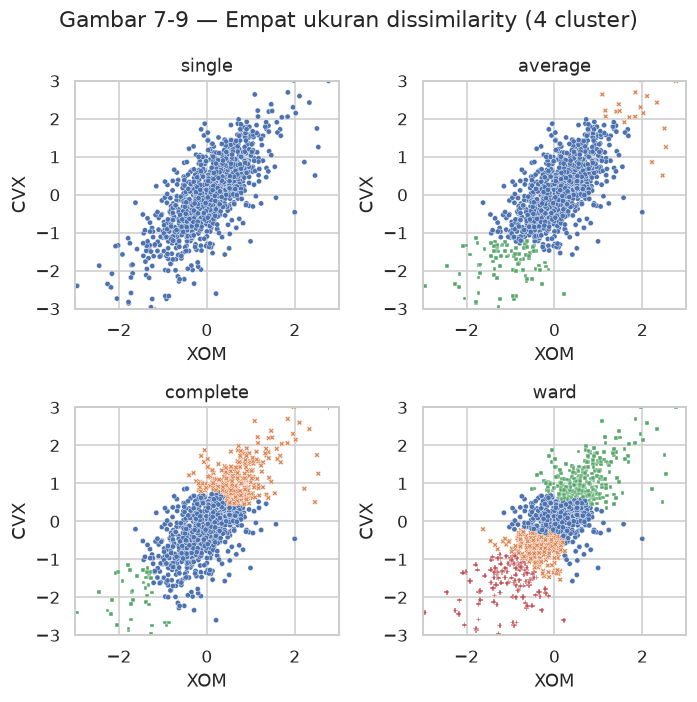

Ukuran 4 cluster per metode (terbesar dulu):


,cluster A,cluster B,cluster C,cluster D
single,1127,2,1,1
average,1015,91,24,1
complete,805,277,44,5
ward,464,290,254,123


In [18]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(6.5, 6.5))
sizes = {}
for i, method in enumerate(['single', 'average', 'complete', 'ward']):
    ax = axes[i // 2, i % 2]
    Z = linkage(df, method=method)
    memb4 = fcluster(Z, 4, criterion='maxclust')
    sizes[method] = sorted(Counter(memb4).values(), reverse=True)
    colors = [f'C{c+1}' for c in memb4]
    ax = sns.scatterplot(x='XOM', y='CVX', hue=colors, style=colors,
                         s=12, ax=ax, data=df, legend=False)
    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(method)
fig.suptitle('Gambar 7-9 — Empat ukuran dissimilarity (4 cluster)')
plt.tight_layout(); plt.show()
print('Ukuran 4 cluster per metode (terbesar dulu):')
display(pd.DataFrame(sizes, index=['cluster A', 'cluster B', 'cluster C', 'cluster D']).T)

**Interpretasi dan catatan belajar.** Ukuran keempat cluster sangat berbeda antar-metode. **Single** linkage menghasilkan satu cluster raksasa (1.127 dari 1.131 hari) dan tiga outlier; ini efek *chaining*, karena dua kelompok cukup dihubungkan oleh satu pasangan titik yang dekat. **Average** (1.015/91/24/1) dan **complete** (805/277/44/5) mulai memisahkan hari naik dan turun ekstrem, sementara **Ward** paling seimbang (464/290/254/123) dan pembagiannya mirip K-means di Gambar 7-5. Pola ini sesuai dengan buku: pilihan linkage bisa mengubah hasil secara drastis, jadi harus disesuaikan dengan tujuan (misalnya single linkage cocok untuk mendeteksi outlier, Ward untuk cluster kompak berukuran mirip).

<a id="c7-16"></a>
## Model-Based Clustering

*Jenis: Teori.*

K-means dan hierarchical clustering adalah heuristik: keduanya tidak memakai model probabilitas. Model-based clustering mengasumsikan setiap cluster berasal dari distribusi statistik tertentu, biasanya **normal multivariat**, sehingga pemilihan jumlah cluster dan bentuk cluster bisa dilakukan dengan kriteria statistik. Pendekatan ini bisa menangkap cluster yang berbentuk elips dengan ukuran berbeda, sesuatu yang sulit bagi K-means.

<a id="c7-17"></a>
## Multivariate Normal Distribution

*Jenis: Reproduksi Python buku + verifikasi tambahan.*

Distribusi normal multivariat untuk $p$ variabel ditentukan oleh vektor rata-rata $\mu$ dan matriks kovarians $\Sigma$, ditulis $X\sim N_p(\mu,\Sigma)$. Kontur densitasnya berbentuk elips. Contoh buku: $\mu=(0{,}5;\,-0{,}5)$ dan $\Sigma=\begin{pmatrix}1&1\\1&2\end{pmatrix}$, dengan kontur yang melingkupi 50%, 75%, 95%, dan 99% peluang. Untuk normal 2 dimensi, daerah $\{x: f(x)>c\}$ dengan $c=\dfrac{1-p}{2\pi\sqrt{|\Sigma|}}$ melingkupi peluang tepat $p$; di kode buku $\sqrt{|\Sigma|}$ ditulis sebagai `D = 1` karena $|\Sigma| = 1\cdot2-1\cdot1 = 1$.

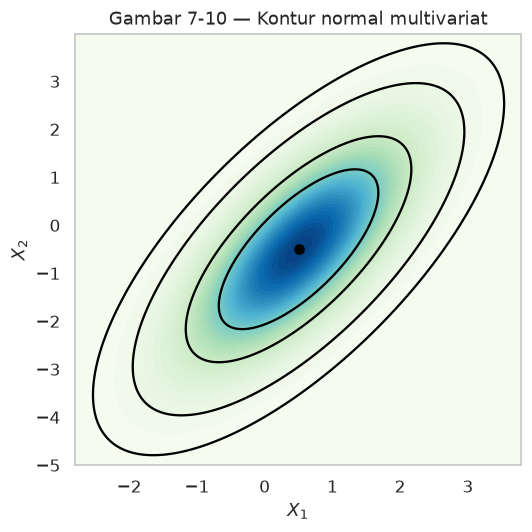

Determinan Sigma: 1.0
p = 0.50: proporsi sampel di dalam kontur = 0.5004
p = 0.75: proporsi sampel di dalam kontur = 0.7501
p = 0.95: proporsi sampel di dalam kontur = 0.9501
p = 0.99: proporsi sampel di dalam kontur = 0.9900


In [19]:
mean = [0.5, -0.5]
cov = [[1, 1], [1, 2]]
probability = [.5, .75, .95, .99]
def probLevel(p):
    D = 1
    return (1 - p) / (2 * math.pi * D)
levels = [probLevel(p) for p in probability]

fig, ax = plt.subplots(figsize=(5, 5))
x, y = np.mgrid[-2.8:3.8:.01, -5:4:.01]
pos = np.empty(x.shape + (2,))
pos[:, :, 0] = x; pos[:, :, 1] = y
rv = multivariate_normal(mean, cov)

CS = ax.contourf(x, y, rv.pdf(pos), cmap=cm.GnBu, levels=50)
ax.contour(CS, levels=sorted(levels), colors=['black'])
ax.plot(*mean, color='black', marker='o')
ax.set(xlabel='$X_1$', ylabel='$X_2$', title='Gambar 7-10 — Kontur normal multivariat')
plt.tight_layout(); plt.show()

# Tambahan: cek Monte Carlo bahwa tiap kontur memang melingkupi peluang p
sample = rv.rvs(size=200_000, random_state=SEED)
dens = rv.pdf(sample)
print('Determinan Sigma:', np.linalg.det(cov))
for p, c in zip(probability, levels):
    print(f'p = {p:.2f}: proporsi sampel di dalam kontur = {np.mean(dens > c):.4f}')

**Interpretasi dan catatan belajar.** Kontur berbentuk elips miring ke kanan atas karena kovarians $X_1,X_2$ positif (korelasi $1/\sqrt{1\cdot 2}\approx0{,}71$), dan lebih memanjang ke arah $X_2$ yang variansinya 2. Cek Monte Carlo dengan 200.000 sampel menghasilkan proporsi 0,5004; 0,7501; 0,9501; 0,9900, sangat dekat dengan 50/75/95/99%, sehingga rumus level kontur di kode buku benar. Satu penyesuaian: kode buku memberi level kontur dalam urutan menurun, sedangkan Matplotlib versi baru mewajibkan urutan naik, jadi di sini dipakai `sorted(levels)`.

<a id="c7-18"></a>
## Mixtures of Normals

*Jenis: Reproduksi Python buku; `random_state` ditambahkan.*

Gaussian mixture model menganggap setiap record berasal dari salah satu dari $K$ distribusi normal multivariat, masing-masing dengan rata-rata $\mu_k$, kovarians $\Sigma_k$, dan bobot $\pi_k$:
$$f(x)=\sum_{k=1}^{K}\pi_k\,N(x;\mu_k,\Sigma_k).$$
Parameter diestimasi dengan algoritme **EM (expectation–maximization)**: langkah E menghitung peluang setiap record termasuk tiap komponen, langkah M memperbarui $\pi_k,\mu_k,\Sigma_k$ dengan peluang itu sebagai bobot. Contoh buku memasang 2 komponen pada XOM–CVX sejak 2011.

BIC (scikit-learn, makin kecil makin baik): 4589.93


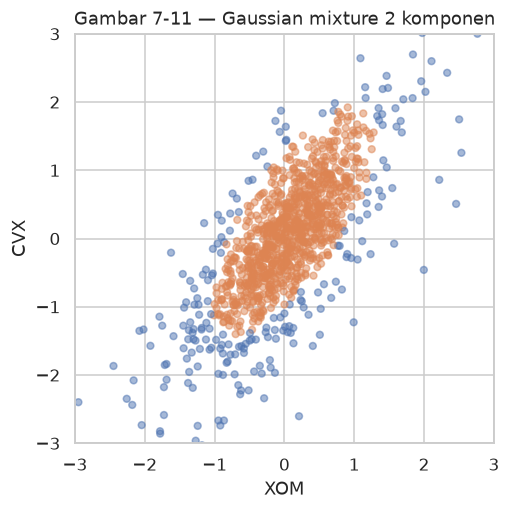

Mean
[[-0.0503 -0.2116]
 [ 0.0725  0.1049]]
Covariances
[[[0.9712 0.9776]
  [0.9776 1.6723]]

 [[0.2682 0.2756]
  [0.2756 0.5168]]]


,bobot pi_k,jumlah hari,sd XOM,sd CVX,korelasi
komponen 0,0.345,215,0.986,1.293,0.767
komponen 1,0.655,916,0.518,0.719,0.740


In [20]:
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
mclust = GaussianMixture(n_components=2, random_state=SEED).fit(df)
print('BIC (scikit-learn, makin kecil makin baik):', round(mclust.bic(df), 2))

fig, ax = plt.subplots(figsize=(4.8, 4.8))
colors = [f'C{c}' for c in mclust.predict(df)]
df.plot.scatter(x='XOM', y='CVX', c=colors, alpha=0.5, ax=ax)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.set_title('Gambar 7-11 — Gaussian mixture 2 komponen')
plt.tight_layout(); plt.show()

print('Mean')
print(mclust.means_.round(4))
print('Covariances')
print(mclust.covariances_.round(4))
# Tambahan: bobot, ukuran, dan standar deviasi tiap komponen
pred = mclust.predict(df)
display(pd.DataFrame({'bobot pi_k': mclust.weights_, 'jumlah hari': np.bincount(pred),
                      'sd XOM': np.sqrt(mclust.covariances_[:, 0, 0]), 'sd CVX': np.sqrt(mclust.covariances_[:, 1, 1]),
                      'korelasi': mclust.covariances_[:, 0, 1] / np.sqrt(mclust.covariances_[:, 0, 0] * mclust.covariances_[:, 1, 1])},
                     index=['komponen 0', 'komponen 1']).round(3))

**Interpretasi dan catatan belajar.** Kedua komponen punya rata-rata dekat nol, jadi yang membedakan adalah **sebaran**, bukan arah. Komponen 1 (bobot 0,655; 916 hari) adalah hari tenang dengan standar deviasi XOM 0,52 dan CVX 0,72. Komponen 0 (bobot 0,345; 215 hari) adalah hari bergejolak dengan standar deviasi kira-kira dua kali lipat (0,99 dan 1,29). Korelasi keduanya mirip (0,74–0,77). Di grafik, satu cluster berada di inti dan cluster lain di pinggiran, persis seperti dijelaskan buku. Ini sangat berbeda dari K-means yang memotong data menurut arah naik/turun: GMM bisa menemukan cluster yang **saling bertumpuk** tetapi berbeda bentuk, karena setiap komponen punya matriks kovarians sendiri.

<a id="c7-19"></a>
## Selecting the Number of Clusters

*Jenis: Reproduksi Python buku; `random_state` ditambahkan.*

Karena GMM adalah model probabilitas, jumlah komponen dan bentuk kovarians bisa dipilih dengan **Bayesian Information Criterion**:
$$\text{BIC} = -2\log\hat L + k\log n,$$
dengan $k$ jumlah parameter dan $n$ jumlah record. Suku kedua menghukum model yang terlalu banyak parameter. Empat tipe kovarians dibandingkan: `full` (setiap komponen punya matriks kovarians sendiri), `tied` (semua komponen berbagi satu matriks), `diag` (hanya variansi, tanpa korelasi), dan `spherical` (satu variansi per komponen). **Perhatian:** di scikit-learn BIC makin kecil makin baik, sedangkan paket R `mclust` yang dipakai buku membalik tanda sehingga makin besar makin baik.

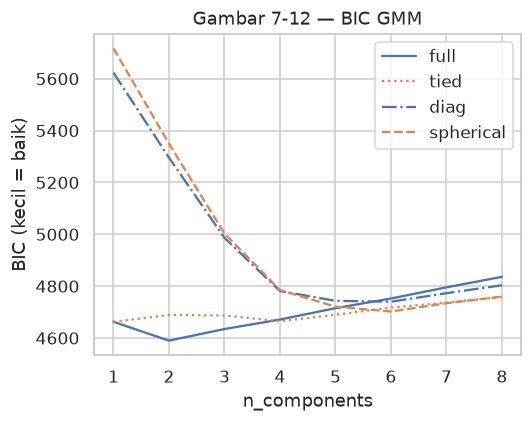

covariance_type,diag,full,spherical,tied
n_components,,,,
1,5623.0,4662.5,5716.7,4662.5
2,5295.7,4589.9,5349.6,4688.8
3,4986.2,4634.6,5002.9,4686.9
4,4781.2,4671.1,4784.9,4664.6
5,4743.4,4715.0,4721.0,4689.7
6,4739.9,4752.4,4702.0,4717.3
7,4772.8,4795.4,4734.0,4736.6
8,4803.4,4835.8,4759.6,4758.2


BIC terkecil: 4589.9 pada 2 komponen, kovarians full


In [21]:
results = []
covariance_types = ['full', 'tied', 'diag', 'spherical']
for n_components in range(1, 9):
    for covariance_type in covariance_types:
        mclust = GaussianMixture(n_components=n_components, warm_start=True,
                                 covariance_type=covariance_type, random_state=SEED)
        mclust.fit(df)
        results.append({
            'bic': mclust.bic(df),
            'n_components': n_components,
            'covariance_type': covariance_type,
        })
results = pd.DataFrame(results)

styles = ['C0-', 'C1:', 'C0-.', 'C1--']
fig, ax = plt.subplots(figsize=(5, 4))
for i, covariance_type in enumerate(covariance_types):
    subset = results.loc[results.covariance_type == covariance_type, :]
    subset.plot(x='n_components', y='bic', ax=ax, label=covariance_type, kind='line', style=styles[i])
ax.set(ylabel='BIC (kecil = baik)', title='Gambar 7-12 — BIC GMM')
plt.tight_layout(); plt.show()

bic_table = results.pivot(index='n_components', columns='covariance_type', values='bic')
display(bic_table.round(1))
best = results.loc[results.bic.idxmin()]
print(f"BIC terkecil: {best.bic:.1f} pada {best.n_components} komponen, kovarians {best.covariance_type}")

**Interpretasi dan catatan belajar.** BIC terkecil (4.589,9) dicapai oleh **2 komponen dengan kovarians full**, sehingga model di bagian sebelumnya memang pilihan terbaik. Untuk satu komponen, full dan tied identik (4.662,5) karena hanya ada satu matriks kovarians. Tipe `diag` dan `spherical` butuh 5–6 komponen untuk mencapai BIC terbaiknya (±4.702–4.740), dan tetap lebih buruk dari full. Penyebabnya, kedua tipe itu tidak bisa memodelkan korelasi XOM–CVX, sehingga harus menumpuk banyak "bola" kecil untuk meniru satu elips miring. Ingat, kalau membandingkan dengan output `mclust` di buku, arah BIC-nya terbalik (di R makin besar makin baik).

<a id="c7-20"></a>
## Scaling and Categorical Variables

*Jenis: Teori.*

Metode unsupervised di bab ini semuanya bertumpu pada jarak atau variansi. Akibatnya variabel dengan satuan besar (misalnya pendapatan tahunan dalam dolar) akan mendominasi variabel bersatuan kecil (misalnya rasio utang dalam persen). Solusi umumnya **standardisasi** (z-score). Untuk PCA, standardisasi setara dengan memakai matriks **korelasi** alih-alih kovarians. Data kategori butuh perlakuan khusus: one-hot encoding membuat variabel biner yang setelah distandardisasi bisa mendominasi, sehingga lebih baik memakai ukuran jarak campuran seperti Gower's distance.

<a id="c7-21"></a>
## Scaling the Variables

*Jenis: Reproduksi Python buku.*

K-means dengan 4 cluster pada pinjaman default memakai 6 variabel: jumlah pinjaman, pendapatan tahunan, saldo kredit bergulir, jumlah akun kredit terbuka, rasio utang (dti), dan pemakaian kredit bergulir (%). Hasil tanpa standardisasi dibandingkan dengan hasil setelah z-score. Pusat cluster setelah z-score dikembalikan ke satuan asli dengan `inverse_transform` agar mudah dibaca.

In [22]:
columns = ['loan_amnt', 'annual_inc', 'revol_bal', 'open_acc', 'dti', 'revol_util']
df = defaults[columns]
display(df.describe().loc[['mean', 'std', 'min', 'max']].round(1))

kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df)
counts = Counter(kmeans.labels_)
centers = pd.DataFrame(kmeans.cluster_centers_, columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print('Tanpa standardisasi:')
display(centers.round(2))

scaler = StandardScaler()
df0 = scaler.fit_transform(df * 1.0)
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
counts = Counter(kmeans.labels_)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print('Dengan standardisasi (pusat dikembalikan ke satuan asli):')
display(centers.round(2))

,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util
mean,13773.2,63586.7,15070.1,10.4,17.2,59.8
std,8329.8,41108.6,19416.1,4.7,7.7,24.5
min,500.0,2000.0,0.0,0.0,0.0,0.0
max,35000.0,932000.0,1207359.0,76.0,36.3,128.1


Tanpa standardisasi:


,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,17809.76,78669.45,18933.41,11.59,17.02,62.18,7906
1,21444.32,148736.06,33152.69,12.38,13.83,63.15,1654
2,24290.91,409746.47,84710.99,13.43,8.15,60.02,88
3,10274.16,41241.21,9950.10,9.48,17.72,57.90,13023


Dengan standardisasi (pusat dikembalikan ke satuan asli):


,loan_amnt,annual_inc,revol_bal,open_acc,dti,revol_util,size
0,13484.73,55907.99,16435.80,14.32,24.21,59.46,6244
1,25950.21,116834.14,32945.97,12.40,16.17,66.12,3670
2,10507.28,51117.99,11635.29,7.51,15.93,77.80,7397
3,10324.85,53456.82,6054.82,8.66,11.31,31.00,5360


**Interpretasi dan catatan belajar.** Tanpa standardisasi, cluster praktis hanya dibedakan oleh `annual_inc` (pusat ±41 ribu, 79 ribu, 149 ribu, dan 410 ribu USD) dan sedikit `revol_bal`, karena standar deviasi keduanya puluhan ribu sedangkan `dti` dan `open_acc` hanya satuan. Variabel kecil nyaris sama di semua cluster (misalnya `revol_util` 58–63%), dan ukurannya sangat timpang: 13.023, 7.906, 1.654, dan **88** pinjaman (kelompok berpendapatan sangat tinggi). Setelah z-score, ukuran cluster lebih seimbang (6.244, 3.670, 7.397, 5.360) dan tiap cluster punya profil multivariabel yang bisa ditafsirkan:

- cluster 0: `dti` tinggi (24,2) dan banyak akun terbuka (14,3);
- cluster 1: pinjaman besar (±25.950) dan pendapatan tinggi (±116.834);
- cluster 2: pemakaian kredit bergulir tinggi (77,8%) dengan sedikit akun (7,5);
- cluster 3: pemakaian kredit rendah (31%), saldo dan `dti` rendah.

Ini sejalan dengan buku: tanpa standardisasi, hasil clustering hanya mencerminkan variabel bersatuan terbesar.

<a id="c7-22"></a>
## Dominant Variables

*Jenis: Reproduksi Python buku + pembanding tambahan.*

Walaupun semua variabel bersatuan sama, variabel yang jauh lebih bervariasi tetap bisa mendominasi. Buku menunjukkan ini dengan PCA pada 18 saham sejak 2005, kali ini termasuk GOOGL dan AMZN yang harga per sahamnya (dan karena itu perubahan harian dalam dolar) jauh lebih besar.

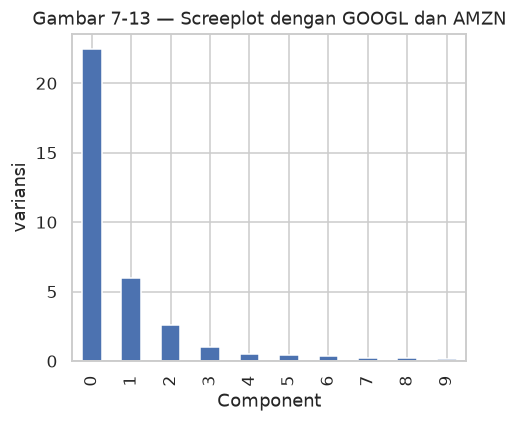

,0,1
GOOGL,0.857,-0.478
AMZN,0.445,0.874
AAPL,0.072,0.021
MSFT,0.036,0.006
CSCO,0.029,0.003
INTC,0.027,0.006
CVX,0.090,0.037
XOM,0.080,0.021
SLB,0.110,0.030
COP,0.058,0.024


In [23]:
syms = ['GOOGL', 'AMZN', 'AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM',
        'SLB', 'COP', 'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST']
top_sp1 = sp500_px.loc[sp500_px.index >= '2005-01-01', syms]

sp_pca1 = PCA()
sp_pca1.fit(top_sp1)

explained_variance = pd.DataFrame(sp_pca1.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4.5, 4))
ax.set_xlabel('Component'); ax.set_ylabel('variansi'); ax.set_title('Gambar 7-13 — Screeplot dengan GOOGL dan AMZN')
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(sp_pca1.components_[0:2, :], columns=top_sp1.columns)
display(loadings.transpose().round(3))

In [24]:
# Tambahan: standar deviasi tiap saham, lalu PCA pada data terstandardisasi (matriks korelasi)
sd = top_sp1.std().sort_values(ascending=False)
print('Standar deviasi perubahan harian (5 terbesar):', sd.head(5).round(2).to_dict())
print('Standar deviasi (5 terkecil):', sd.tail(5).round(2).to_dict())
sp_pca_std = PCA().fit(StandardScaler().fit_transform(top_sp1))
display(pd.DataFrame({'tanpa standardisasi': sp_pca1.explained_variance_ratio_[:5],
                      'dengan standardisasi': sp_pca_std.explained_variance_ratio_[:5]},
                     index=[f'PC{i+1}' for i in range(5)]).round(4))
display(pd.DataFrame({'PC1 standar': sp_pca_std.components_[0], 'PC2 standar': sp_pca_std.components_[1]},
                     index=syms).round(3).T)

Standar deviasi perubahan harian (5 terbesar): {'GOOGL': 4.23, 'AMZN': 3.01, 'SLB': 1.25, 'CVX': 0.95, 'XOM': 0.85}
Standar deviasi (5 terkecil): {'WMT': 0.51, 'USB': 0.45, 'MSFT': 0.34, 'CSCO': 0.28, 'INTC': 0.27}


,tanpa standardisasi,dengan standardisasi
PC1,0.6472,0.4455
PC2,0.1717,0.0958
PC3,0.0740,0.0686
PC4,0.0294,0.0565
PC5,0.0149,0.0457


,GOOGL,AMZN,AAPL,MSFT,CSCO,INTC,CVX,XOM,SLB,COP,JPM,WFC,USB,AXP,WMT,TGT,HD,COST
PC1 standar,0.220,0.186,0.176,0.236,0.252,0.237,0.253,0.257,0.216,0.232,0.267,0.264,0.260,0.266,0.217,0.231,0.222,0.227
PC2 standar,-0.044,-0.045,-0.032,-0.007,-0.034,-0.038,0.418,0.379,0.413,0.457,-0.138,-0.157,-0.192,-0.098,-0.231,-0.254,-0.204,-0.208


**Interpretasi dan catatan belajar.** Dengan GOOGL dan AMZN, PC1 dan PC2 menjelaskan 64,7% dan 17,2% variansi, tetapi isinya hampir hanya dua saham itu: PC1 = (GOOGL 0,857; AMZN 0,445), PC2 = (GOOGL −0,478; AMZN 0,874), sementara loadings 16 saham lain di bawah 0,11. Sebabnya terlihat dari standar deviasi: GOOGL 4,23 dan AMZN 3,01, sedangkan saham lain 0,27–1,25. Setelah standardisasi (PCA berbasis korelasi), PC1 menjelaskan 44,6% dengan loadings merata 0,18–0,27 untuk semua saham (faktor pasar), dan PC2 (9,6%) kembali menjadi kontras energi (0,38–0,46) vs saham lain. Buku menyarankan dua solusi: standardisasi, atau keluarkan variabel dominan dan analisis terpisah. Keduanya mengembalikan struktur yang ditemukan di analisis 16 saham.

<a id="c7-23"></a>
## Categorical Data and Gower's Distance

*Jenis: Tambahan Python untuk contoh R buku (Gower ditulis manual).*

Gower's distance menangani data campuran dengan menghitung jarak per variabel lalu merata-ratakannya:
- variabel **numerik**: $d_j = |x_{ij}-x_{kj}|/R_j$, dengan $R_j$ rentang (max − min) variabel itu, sehingga nilainya 0–1;
- variabel **kategori**: $d_j = 0$ jika kategorinya sama, 1 jika berbeda.

$$d_{\text{Gower}}(i,k)=\frac{1}{p}\sum_{j=1}^{p} d_j(i,k).$$

Kode Python buku tidak menyediakan Gower (hanya komentar berisi kode R `daisy(x, metric='gower')`). Fungsi kecil di bawah menghitungnya dengan definisi yang sama seperti `daisy`. Contoh pertama memakai 5 pinjaman pertama dengan dua variabel numerik (`dti`, `payment_inc_ratio`) dan dua kategori (`home_`, `purpose_`). Kode Python buku memakai `.loc[0:4]` pada indeks bawaan; karena file di sini dibaca dengan `index_col=0`, dipakai `.iloc[0:5]` agar barisnya sama.

In [25]:
def gower_matrix(data):
    # Gower's distance untuk DataFrame campuran numerik dan kategori (setara cluster::daisy metric='gower')
    n = len(data)
    total = np.zeros((n, n))
    for col in data.columns:
        values = data[col]
        if pd.api.types.is_numeric_dtype(values):
            v = values.to_numpy(dtype=float)
            rng_ = v.max() - v.min()
            d = np.abs(v[:, None] - v[None, :]) / (rng_ if rng_ > 0 else 1)
        else:
            v = values.astype(str).to_numpy()
            d = (v[:, None] != v[None, :]).astype(float)
        total += d
    return pd.DataFrame(total / data.shape[1], index=data.index, columns=data.index)

x = defaults[['dti', 'payment_inc_ratio', 'home_', 'purpose_']].iloc[0:5, :]
display(x)
G = gower_matrix(x)
display(G.round(4))

,dti,payment_inc_ratio,home_,purpose_
1,1.00,2.39320,RENT,major_purchase
2,5.55,4.57170,OWN,small_business
3,18.08,9.71600,RENT,other
4,10.08,12.21520,RENT,debt_consolidation
5,7.06,3.90888,RENT,other


,1,2,3,4,5
1,0.0000,0.6220,0.6864,0.6329,0.3773
2,0.6220,0.0000,0.8143,0.7609,0.5390
3,0.6864,0.8143,0.0000,0.4307,0.3091
4,0.6329,0.7609,0.4307,0.0000,0.5056
5,0.3773,0.5390,0.3091,0.5056,0.0000


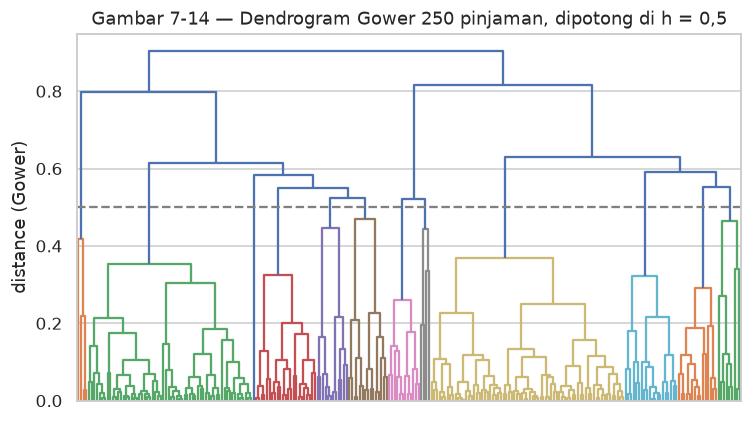

Jumlah cluster setelah dipotong di 0,5: 12


,n,home_terbanyak,home_murni,purpose_terbanyak,purpose_murni,dti_mean,pir_mean
cluster,,,,,,,
9,73,RENT,True,debt_consolidation,True,17.21,9.07
2,62,MORTGAGE,True,debt_consolidation,True,16.24,7.50
3,23,MORTGAGE,True,credit_card,True,17.52,8.07
10,20,RENT,True,credit_card,True,16.50,8.18
5,15,MORTGAGE,True,home_improvement,False,15.08,5.84
11,15,RENT,True,other,True,16.92,7.18
7,12,OWN,True,debt_consolidation,True,18.81,8.36
4,12,MORTGAGE,True,major_purchase,False,14.57,4.87
12,9,RENT,True,small_business,False,9.25,7.87


Isi cluster paling kiri di dendrogram (cluster 1):


,dti,payment_inc_ratio,home_,purpose_
10840,14.75,2.37586,RENT,major_purchase
33768,7.65,16.19490,RENT,major_purchase
33809,11.89,1.84537,RENT,major_purchase
38139,6.12,3.36576,OWN,major_purchase


In [26]:
# Tambahan: hierarchical clustering dengan Gower pada 250 pinjaman acak (seperti contoh R buku)
sample250 = loan_data.sample(250, random_state=301)[['dti', 'payment_inc_ratio', 'home_', 'purpose_']]
G250 = gower_matrix(sample250)
Z_gower = linkage(squareform(G250.to_numpy(), checks=False), method='complete')
fig, ax = plt.subplots(figsize=(7, 4))
dendrogram(Z_gower, no_labels=True, color_threshold=0.5, ax=ax)
ax.axhline(0.5, ls='--', color='grey')
ax.set(ylabel='distance (Gower)', title='Gambar 7-14 — Dendrogram Gower 250 pinjaman, dipotong di h = 0,5')
plt.tight_layout(); plt.show()

cut = pd.Series(fcluster(Z_gower, t=0.5, criterion='distance'), index=sample250.index, name='cluster')
print('Jumlah cluster setelah dipotong di 0,5:', cut.nunique())
summary_g = sample250.assign(cluster=cut).groupby('cluster').agg(
    n=('dti', 'size'),
    home_terbanyak=('home_', lambda s: s.mode().iat[0]), home_murni=('home_', lambda s: s.nunique() == 1),
    purpose_terbanyak=('purpose_', lambda s: s.mode().iat[0]), purpose_murni=('purpose_', lambda s: s.nunique() == 1),
    dti_mean=('dti', 'mean'), pir_mean=('payment_inc_ratio', 'mean'))
display(summary_g.sort_values('n', ascending=False).round(2))
leaves = dendrogram(Z_gower, no_plot=True)['leaves']     # urutan daun dari kiri ke kanan
first = cut.iloc[leaves[0]]
print(f'Isi cluster paling kiri di dendrogram (cluster {first}):')
display(sample250[cut == first].head(10))

**Interpretasi dan catatan belajar.** Matriks Gower 5×5 cocok dengan output `daisy` di buku sampai 4 desimal (0,6220; 0,6864; 0,6329; 0,3773; 0,8143; …). Pasangan paling mirip adalah pinjaman 3 dan 5 (0,309): keduanya RENT dengan tujuan *other*, perbedaannya hanya di variabel numerik. Pasangan paling berbeda adalah 2 dan 3 (0,814): kedua kategorinya berbeda dan `dti`-nya jauh berbeda.

Pada 250 pinjaman acak, pemotongan dendrogram di 0,5 menghasilkan 12 cluster. Hampir semuanya **murni** dalam `home_` (11 dari 12) dan sebagian besar murni dalam `purpose_` (7 dari 12). Dua cluster terbesar adalah RENT + debt_consolidation (73) dan MORTGAGE + debt_consolidation (62). Cluster paling kiri berisi 4 pinjaman yang semuanya *major_purchase*. Jadi dengan Gower, variabel kategori cenderung menentukan cluster: perbedaan kategori langsung bernilai 1, sedangkan perbedaan numerik dibagi rentang sehingga biasanya kecil. Sampel R buku (`set.seed(301)`) tidak bisa diulang persis di Python, sehingga isi cluster berbeda, tetapi polanya sama.

<a id="c7-24"></a>
## Problems with Clustering Mixed Data

*Jenis: Reproduksi Python buku.*

Apa yang terjadi kalau variabel kategori di-one-hot lalu langsung dipakai K-means? Contoh buku memakai `dti`, `payment_inc_ratio`, `home_` (tiga dummy), dan `pub_rec_zero` (biner) pada pinjaman default, distandardisasi, lalu dibagi 4 cluster.

In [27]:
columns = ['dti', 'payment_inc_ratio', 'home_', 'pub_rec_zero']
df = pd.get_dummies(defaults[columns], dtype=int)

scaler = StandardScaler()
df0 = scaler.fit_transform(df * 1.0)
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=df.columns)
centers['size'] = pd.Series(Counter(kmeans.labels_)).sort_index().to_numpy()
display(centers.round(2) + 0)    # + 0 menghilangkan tampilan -0.0

,dti,payment_inc_ratio,pub_rec_zero,home__MORTGAGE,home__OWN,home__RENT,size
0,21.43,12.35,0.94,0.0,0.0,1.0,5363
1,12.74,5.92,0.90,0.0,0.0,1.0,5641
2,17.34,8.35,0.91,1.0,0.0,0.0,9779
3,17.20,9.27,0.92,0.0,1.0,0.0,1888


**Interpretasi dan catatan belajar.** Keempat cluster ternyata dibentuk oleh kategori `home_`: cluster 2 = semua MORTGAGE (9.779), cluster 3 = semua OWN (1.888), sedangkan cluster 0 dan 1 = RENT yang dipecah lagi menurut variabel numerik (`dti` 21,4 vs 12,7; `payment_inc_ratio` 12,4 vs 5,9). `pub_rec_zero` hampir sama di semua cluster (0,90–0,94). Seperti dijelaskan buku, dummy biner setelah distandardisasi punya jarak antarnilai yang besar dibanding variasi variabel numerik, sehingga K-means cenderung "memotong" data menurut kategori. Kalau data campuran harus di-cluster, gunakan Gower + hierarchical clustering, atau pertimbangkan bobot/skala ulang dummy.

<a id="c7-25"></a>
## Summary

*Jenis: Teori.*

PCA, correspondence analysis, dan clustering adalah alat untuk **memahami struktur data tanpa target**. Hasil bab ini memperlihatkan beberapa pelajaran yang berulang:

- PCA pada 16 saham menemukan faktor pasar (44,5% variansi) dan kontras energi vs non-energi; correspondence analysis memetakan pembagian kerja rumah tangga dengan 88,6% inertia dalam dua dimensi.
- K-means membagi hari perdagangan menjadi pola pasar naik/turun dan pola khas sektor, tetapi silhouette yang rendah (±0,1–0,2) menunjukkan cluster-nya tidak terpisah tegas; elbow tidak selalu memberi jawaban jelas.
- Hierarchical clustering memberi dendrogram yang mudah dibaca, tetapi hasilnya sangat bergantung pada linkage (single: 1 cluster raksasa; Ward: cluster seimbang).
- Gaussian mixture memisahkan hari tenang dan hari bergejolak, sesuatu yang tidak bisa dilakukan K-means, dan BIC memilih 2 komponen dengan kovarians full.
- Skala menentukan segalanya: tanpa standardisasi, `annual_inc` mendominasi cluster pinjaman dan GOOGL/AMZN mendominasi PCA saham. Data kategori butuh jarak khusus seperti Gower; kalau di-one-hot lalu dimasukkan ke K-means, cluster cenderung hanya mengikuti kategori.

**Latihan:** jelaskan mengapa loadings PCA boleh berganti tanda tanpa mengubah tafsir; hitung Gower's distance pinjaman 1 dan 2 secara manual dari tabel di atas; ulangi hierarchical clustering 18 saham setelah standardisasi dan bandingkan cluster-nya dengan sektor; jelaskan mengapa single linkage cocok untuk mendeteksi outlier; jalankan K-means pada data pinjaman terstandardisasi dengan k=2…8 lalu pilih k dengan silhouette.

**Batas hasil:** data saham adalah perubahan harga harian dalam dolar sesuai file buku (bukan return persen), sehingga saham berharga mahal otomatis lebih volatil. Hasil clustering bergantung pada seed, sampel, dan pilihan skala; cluster adalah ringkasan deskriptif, bukan kelompok "sebenarnya" yang pasti ada di populasi.

## Referensi dan atribusi

- Peter Bruce, Andrew Bruce, Peter Gedeck. *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, edisi 2, O’Reilly, 2020. ISBN 978-1-492-07294-2, Bab 7.
- [Kode dan dataset resmi pada commit tetap](https://github.com/gedeck/practical-statistics-for-data-scientists/tree/8a6d3bb6468e979c861d4b37215e1413702dfdfa); sumber khusus: `python/code/Chapter 7 - Unsupervised Learning.py` (dan kode R yang dikomentari di file itu untuk Gower's distance). Copyright kode upstream © 2019 Peter C. Bruce, Andrew Bruce, Peter Gedeck. Modifikasi untuk tugas: penjelasan Indonesia, `random_state` eksplisit, label grafik, fungsi Gower manual, serta contoh tambahan (verifikasi eigen, algoritme Lloyd dan agglomerative manual, persen variansi dan silhouette, cek Monte Carlo kontur normal, PCA terstandardisasi) yang ditandai. Lisensi GPL-3.0: lihat [LICENSE](LICENSE).
- J. C. Gower (1971). A General Coefficient of Similarity and Some of Its Properties. *Biometrics*, 27(4), 857–871.
- Dokumentasi [scikit-learn](https://scikit-learn.org/), [SciPy cluster.hierarchy](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html), dan [prince](https://github.com/MaxHalford/prince).

**Refleksi mahasiswa:**